# Parquet vs Delta vs Iceberg: comparación final

Resumen de las mediciones del proyecto sobre las mismas tablas de viajes de taxi de NYC (enero a marzo de 2025, 11.2 M de filas) en tres formatos:

| Formato | Tabla |
|---|---|
| Parquet | `data/interim/yellow_tripdata.parquet`: un archivo, sin formato de tabla (línea base) |
| Delta | `data/delta/yellow_tripdata_pyarrow` |
| Iceberg | `lakehouse.yellow_tripdata`, en el catálogo SQLite `data/iceberg/catalog.db` |

El notebook no repite el trabajo del pipeline: lee lo que este dejó y mide lo que falta.

1. **Consultas con DuckDB:** la ejecución más reciente de `lh-bench-formats`, guardada en `data/benchmarks/resultados.duckdb`.
2. **Medición en vivo:** las mismas seis consultas, repetidas ahora, para comprobar que el orden se mantiene.
3. **Tamaño en disco:** versión actual y todo el directorio, con los archivos que guarda el *time travel*.
4. **Cómo están escritos los archivos:** archivos, row groups y compresión de cada tabla, que explican los tiempos de Iceberg.
5. **Escritura con Spark:** la actualización de febrero de la semana 2 (`docs/spark/update_month_*.json`).

Se ejecuta desde la raíz del repositorio, después de `make pipeline` (o dentro de Docker, después de `make demo`):

```bash
make notebook    # ejecuta el notebook y guarda las salidas en el mismo archivo
```

In [1]:
import json
import os
from pathlib import Path

# El notebook está en notebooks/; las rutas del proyecto son relativas a la raíz.
if Path.cwd().name == 'notebooks':
    os.chdir('..')

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import pandas as pd
import pyarrow.parquet as pq
from deltalake import DeltaTable
from pyiceberg.table import StaticTable

from lakehouse.benchmarks import formats
from lakehouse.benchmarks.queries import FORMATS
from lakehouse.benchmarks.results_db import RESULTS_DB
from lakehouse.dashboard import data
from lakehouse.dashboard.charts import colors
from lakehouse.paths import DOCS_DIR

# lakehouse.benchmarks.charts fija el backend Agg para guardar PNG; aquí se quieren las gráficas en el notebook.
%matplotlib inline

pd.options.display.float_format = '{:,.1f}'.format
COLORS = colors()
NAMES = {'parquet': 'Parquet', 'delta': 'Delta', 'iceberg': 'Iceberg'}

run = data.runs(RESULTS_DB)[0]
times = data.load_times(RESULTS_DB, run)
sizes = data.load_sizes(RESULTS_DB, run)

print(f'Ejecución del benchmark: {run:%Y-%m-%d %H:%M:%S}')
print(f'Repeticiones por consulta y formato: {times["repeticiones"].iloc[0]}')

Ejecución del benchmark: 2026-10-26 10:34:47
Repeticiones por consulta y formato: 10


## 1. Consultas con DuckDB

Seis consultas con el mismo texto SQL en los tres formatos; solo cambia la función que crea la vista `trips` (`read_parquet`, `delta_scan` o `iceberg_scan`). Tiempos en ms, mediana de las repeticiones medidas, después de 2 de calentamiento.

In [2]:
def by_format(df: pd.DataFrame, value: str) -> pd.DataFrame:
    """Una fila por consulta y una columna por formato, en el orden de FORMATS."""
    return df.pivot(index='consulta', columns='formato', values=value)[list(FORMATS)]


median = by_format(times, 'mediana_ms')
summary = median.copy()
summary.loc['Total'] = median.sum()
summary['más rápido'] = summary[list(FORMATS)].idxmin(axis=1).map(NAMES)
summary

formato,parquet,delta,iceberg,más rápido
consulta,,,,
q1_conteo,18.1,7.2,2.1,Iceberg
q2_por_mes,58.2,36.2,148.6,Delta
q3_filtro_febrero,53.9,41.4,176.8,Delta
q4_top_zonas,49.9,38.5,95.5,Delta
q5_por_hora,99.2,80.3,218.3,Delta
q6_propina_por_pago,75.2,57.9,145.0,Delta
Total,354.5,261.4,786.4,Delta


In [3]:
relative = median.div(median['parquet'], axis=0)
relative.loc['Total'] = summary.loc['Total', list(FORMATS)].astype(float) / summary.loc['Total', 'parquet']
relative.style.format('{:.2f}x')

formato,parquet,delta,iceberg
consulta,,,
q1_conteo,1.00x,0.40x,0.12x
q2_por_mes,1.00x,0.62x,2.55x
q3_filtro_febrero,1.00x,0.77x,3.28x
q4_top_zonas,1.00x,0.77x,1.91x
q5_por_hora,1.00x,0.81x,2.20x
q6_propina_por_pago,1.00x,0.77x,1.93x
Total,1.00x,0.74x,2.22x


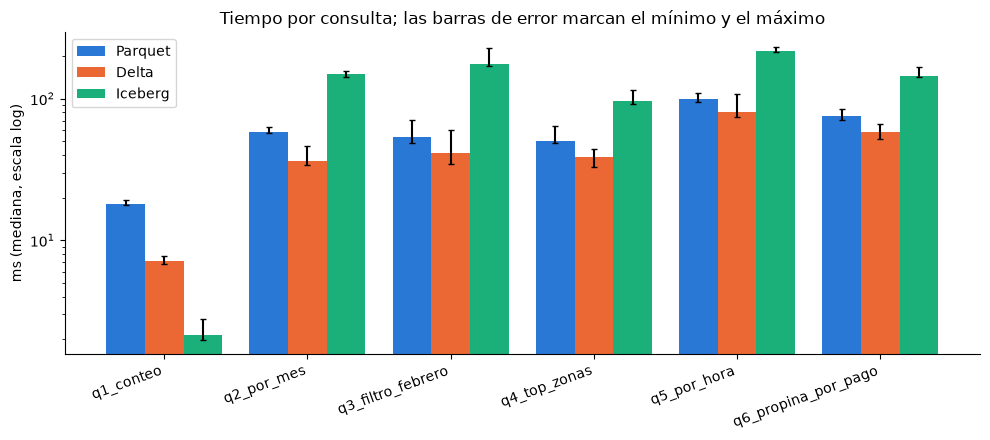

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.5))
width = 0.27

for i, format_ in enumerate(FORMATS):
    x = [j + (i - 1) * width for j in range(len(median))]
    err = by_format(times, 'min_ms')[format_], by_format(times, 'max_ms')[format_]
    yerr = [median[format_] - err[0], err[1] - median[format_]]
    ax.bar(x, median[format_], width, label=NAMES[format_], color=COLORS[format_], yerr=yerr, capsize=2)

ax.set_xticks(range(len(median)), median.index, rotation=20, ha='right')
ax.set_yscale('log')
ax.set_ylabel('ms (mediana, escala log)')
ax.set_title('Tiempo por consulta; las barras de error marcan el mínimo y el máximo')
ax.legend()
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()

**Dispersión.** Rango entre el mínimo y el máximo, como porcentaje de la mediana. Si es pequeño frente a las diferencias entre formatos, el orden no se debe al ruido.

In [5]:
spread = (by_format(times, 'max_ms') - by_format(times, 'min_ms')) / median * 100
spread.style.format('{:.0f} %')

formato,parquet,delta,iceberg
consulta,,,
q1_conteo,8 %,12 %,37 %
q2_por_mes,9 %,33 %,9 %
q3_filtro_febrero,40 %,60 %,32 %
q4_top_zonas,30 %,29 %,23 %
q5_por_hora,14 %,41 %,9 %
q6_propina_por_pago,17 %,24 %,18 %


## 2. Medición en vivo

Las mismas seis consultas, con 5 repeticiones y 1 de calentamiento, sobre las tablas actuales. `formats.run` es la misma función que usa `lh-bench-formats`, y `compare_results` comprueba que los tres formatos devuelvan el mismo resultado. Los valores absolutos dependen de la máquina; lo que se compara es el orden.

In [6]:
locations = {
    'parquet': str(formats.PARQUET),
    'delta': str(formats.DELTA),
    'iceberg': formats.iceberg_location(),
}
live, results = formats.run(locations, repetitions=5, warmup=1)
differences = formats.compare_results(results)

live_ms = pd.DataFrame(
    [{'consulta': m.query, 'formato': m.format_, 'mediana_ms': m.median_s * 1000} for m in live]
).pipe(by_format, 'mediana_ms')
live_ms.loc['Total'] = live_ms.sum()

comparison = pd.DataFrame({
    'más rápido (benchmark)': summary['más rápido'],
    'más rápido (ahora)': live_ms.idxmin(axis=1).map(NAMES),
})
comparison['coincide'] = comparison.iloc[:, 0] == comparison.iloc[:, 1]

print('Resultados iguales en los tres formatos:', 'sí' if not differences else differences)
live_ms.join(comparison)

Resultados iguales en los tres formatos: sí


,parquet,delta,iceberg,más rápido (benchmark),más rápido (ahora),coincide
consulta,,,,,,
q1_conteo,18.6,7.9,2.2,Iceberg,Iceberg,True
q2_por_mes,63.8,39.0,151.6,Delta,Delta,True
q3_filtro_febrero,51.4,36.5,176.0,Delta,Delta,True
q4_top_zonas,54.0,35.2,96.9,Delta,Delta,True
q5_por_hora,103.3,85.3,224.0,Delta,Delta,True
q6_propina_por_pago,70.4,53.5,142.4,Delta,Delta,True
Total,361.5,257.3,793.1,Delta,Delta,True


## 3. Tamaño en disco

- **Versión actual:** los archivos de datos que lee una consulta hoy (el log de Delta, `inspect.files()` de Iceberg).
- **En disco:** todo el directorio, con los metadatos y los archivos de versiones anteriores que se guardan para el *time travel*, hasta un `VACUUM` (Delta) o hasta expirar los snapshots (Iceberg).

In [7]:
size_table = sizes.set_index('formato').rename(index=NAMES)
size_table['historial_mb'] = size_table['disco_mb'] - size_table['actual_mb']
size_table

,archivos,actual_mb,disco_mb,historial_mb
formato,,,,
Parquet,1,195.6,195.6,0.0
Delta,6,220.2,290.7,70.5
Iceberg,5,181.1,240.9,59.8


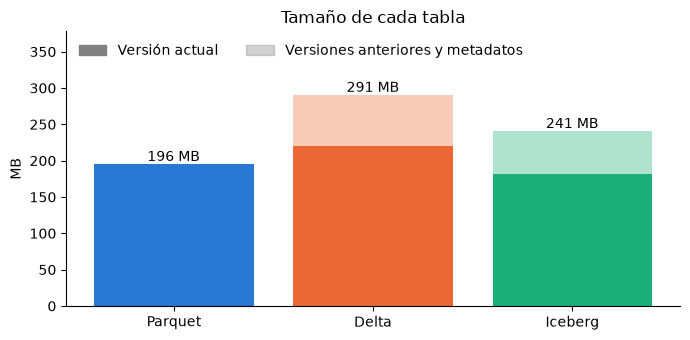

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.5))
labels = size_table.index
ax.bar(labels, size_table['actual_mb'], color=[COLORS[f] for f in FORMATS])
ax.bar(labels, size_table['historial_mb'], bottom=size_table['actual_mb'],
       color=[COLORS[f] for f in FORMATS], alpha=0.35)

for x, (actual, disk) in enumerate(zip(size_table['actual_mb'], size_table['disco_mb'])):
    ax.text(x, disk + 4, f'{disk:.0f} MB', ha='center')

ax.set_ylabel('MB')
ax.set_ylim(0, size_table['disco_mb'].max() * 1.3)
ax.set_title('Tamaño de cada tabla')
ax.legend(handles=[Patch(color='gray', label='Versión actual'),
                   Patch(color='gray', alpha=0.35, label='Versiones anteriores y metadatos')],
          loc='upper left', ncols=2, frameon=False)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()

## 4. Cómo están escritos los archivos

DuckDB reparte el trabajo entre hilos por *row group*, así que un archivo grande con un solo row group lo lee un solo hilo. La tabla lista cada archivo de datos de la versión actual con sus filas, row groups y códec, leídos del pie de cada Parquet.

In [9]:
def data_files() -> dict[str, list[str]]:
    """Archivos de datos de la versión actual de cada tabla."""
    iceberg = StaticTable.from_metadata(locations['iceberg']).inspect.files()

    return {
        'parquet': [locations['parquet']],
        'delta': DeltaTable(locations['delta']).file_uris(),
        'iceberg': [p.removeprefix('file:') for p in iceberg['file_path'].to_pylist()],
    }


rows = []
for format_, paths in data_files().items():
    for path in paths:
        meta = pq.ParquetFile(path).metadata
        rows.append({
            'formato': NAMES[format_],
            'archivo': Path(path).name[:40],
            'filas': meta.num_rows,
            'row_groups': meta.num_row_groups,
            'compresión': meta.row_group(0).column(0).compression,
            'mb': Path(path).stat().st_size / 2**20,
        })

files = pd.DataFrame(rows)
files.groupby('formato', sort=False).agg(
    archivos=('archivo', 'count'),
    row_groups=('row_groups', 'sum'),
    filas_por_row_group=('filas', lambda s: s.sum() / files.loc[s.index, 'row_groups'].sum()),
    compresión=('compresión', lambda s: ', '.join(sorted(set(s)))),
).style.format({'filas_por_row_group': '{:,.0f}'})

,archivos,row_groups,filas_por_row_group,compresión
formato,,,,
Parquet,1,173,"64,728",ZSTD
Delta,6,12,"933,167",SNAPPY
Iceberg,5,11,"1,018,000","GZIP, ZSTD"


In [10]:
files.sort_values(['formato', 'row_groups']).style.format({'filas': '{:,}', 'mb': '{:.1f}'})

,formato,archivo,filas,row_groups,compresión,mb
1,Delta,part-00001-5a0da745-beaa-4136-b829-b1192,"1,048,576",1,SNAPPY,20.8
2,Delta,part-00005-b233472a-13b2-4965-aacc-8db65,"1,048,576",1,SNAPPY,20.8
3,Delta,part-00008-9801cbf5-79e1-480e-94af-ec48b,"1,048,576",1,SNAPPY,20.3
4,Delta,part-00010-430dba1c-ddda-42ea-b3be-0c3bc,"431,814",1,SNAPPY,8.1
5,Delta,part-00000-07b29694-7f69-4c7c-9d95-7a67c,"3,475,234",4,SNAPPY,68.8
6,Delta,part-00000-8aa54b6b-808b-4cac-8f7a-0cc91,"4,145,225",4,SNAPPY,81.3
7,Iceberg,00000-390-9d3ad8f7-efc5-423a-bfbb-360c0b,"3,577,542",1,GZIP,54.4
9,Iceberg,00000-1-ddaa37ee-83e8-4dab-af59-fe3134ca,"734,439",1,ZSTD,12.6
11,Iceberg,00000-1-37914491-12c6-4b49-9aeb-26433c66,"65,872",1,ZSTD,1.2
8,Iceberg,00000-0-ddaa37ee-83e8-4dab-af59-fe3134ca,"3,410,786",4,ZSTD,56.1


El archivo de Iceberg con un solo row group y compresión GZIP es febrero: lo reescribió Spark en la semana 2 con el códec por defecto de Iceberg en Java. Ese archivo explica la mayor parte de la diferencia en las consultas que recorren toda la tabla.

## 5. Escritura con Spark: actualizar un mes completo

En la semana 2, `lh-spark-update-month --mes 2025-02` reemplazó los cargos nulos de febrero por 0.0 y reescribió el mes en Delta (`replaceWhere`) y en Iceberg (`overwritePartitions`). Estas son sus mediciones.

In [11]:
update = json.loads(max((DOCS_DIR / 'spark').glob('update_month_*.json')).read_text())
MB = 2**20

pd.DataFrame({
    r['formato']: {
        'segundos': r['segundos'],
        'operación': r['operacion'],
        'compresión nueva': r['compresion'],
        'archivos del mes (antes → después)': f"{r['archivos_mes_antes']} → {r['archivos_mes_despues']}",
        'MB del mes (antes → después)': f"{r['bytes_mes_antes'] / MB:.1f} → {r['bytes_mes_despues'] / MB:.1f}",
        'nulos (antes → después)': f"{r['nulos_antes']:,} → {r['nulos_despues']:,}",
        'archivos de metadatos nuevos': r['metadatos_nuevos'],
        'otros meses sin cambios': r['otros_meses_ok'],
    }
    for r in update['resultados']
})

,Delta,Iceberg
segundos,12.3,14.9
operación,WRITE,overwrite
compresión nueva,SNAPPY,GZIP
archivos del mes (antes → después),1 → 4,2 → 1
MB del mes (antes → después),70.0 → 70.0,59.3 → 54.4
nulos (antes → después),"806,937 → 0","806,937 → 0"
archivos de metadatos nuevos,4,8
otros meses sin cambios,True,True


## Conclusiones

La celda siguiente resume las cifras de esta ejecución; el resto son lo que se comprobó en las tres semanas.

In [12]:
total = summary.loc['Total', list(FORMATS)].astype(float)
wins = summary.drop('Total')['más rápido'].value_counts()

print(f"Total de las 6 consultas: " + ', '.join(f'{NAMES[f]} {total[f]:.0f} ms' for f in FORMATS))
print(f"Consultas ganadas: " + ', '.join(f'{k} {v}' for k, v in wins.items()))
print(f"Delta frente a Parquet: {total['delta'] / total['parquet']:.2f}x; Iceberg: {total['iceberg'] / total['parquet']:.2f}x")
print(f"Historial en disco: Delta {size_table.loc['Delta', 'historial_mb']:.0f} MB, "
      f"Iceberg {size_table.loc['Iceberg', 'historial_mb']:.0f} MB")

Total de las 6 consultas: Parquet 354 ms, Delta 261 ms, Iceberg 786 ms
Consultas ganadas: Delta 5, Iceberg 1
Delta frente a Parquet: 0.74x; Iceberg: 2.22x
Historial en disco: Delta 71 MB, Iceberg 60 MB


- **Delta fue el más rápido con DuckDB** en las consultas que recorren la tabla, incluso frente al Parquet sin formato de tabla: sus archivos tienen más row groups (más paralelismo) y usan SNAPPY, que descomprime más rápido que ZSTD.
- **Iceberg ganó el `count(*)`** porque lo responde con los conteos de los manifiestos, sin abrir los datos. En el resto fue el más lento por cómo quedaron escritos sus archivos (febrero en GZIP y un solo row group), no por el formato: el siguiente paso es fijar `write.parquet.compression-codec=zstd`, compactar con `rewrite_data_files` y repetir la medición.
- **El *pruning* funciona en los dos formatos de tabla** filtrando por la fecha original, sin mencionar las columnas de partición (en Iceberg, gracias al *hidden partitioning*).
- **El historial cuesta espacio.** Delta y Iceberg guardan los archivos reemplazados para el *time travel* hasta que se limpian; Parquet no tiene historial ni valida el esquema al escribir.
- **Para elegir:** Parquet para datos de solo lectura que se reemplazan completos; Delta si el motor principal es Spark o DuckDB y se necesitan `MERGE` y *time travel* con poca configuración; Iceberg si varias herramientas comparten la tabla a través de un catálogo, o se necesita cambiar la partición sin reescribir los datos. La pestaña *Guía de formatos* del dashboard desarrolla esta tabla.